In [ ]:
!pip install pandas numpy matplotlib statsmodels scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print(df.head())
print(df.columns.tolist())
print(df.shape)

Saving daily-demand-series.csv to daily-demand-series (1).csv
Dataset loaded successfully!
         date  demand  marketing_event  holiday
0  2026-06-01     118                0        0
1  2026-06-02     121                0        0
2  2026-06-03     125                0        0
3  2026-06-04     123                0        0
4  2026-06-05     137                1        0
['date', 'demand', 'marketing_event', 'holiday']
(30, 4)


In [ ]:
df.head()

,date,demand,marketing_event,holiday
0,2026-06-01,118,0,0
1,2026-06-02,121,0,0
2,2026-06-03,125,0,0
3,2026-06-04,123,0,0
4,2026-06-05,137,1,0


In [ ]:
# Find the date column
date_col = next(
    (c for c in df.columns
     if "date" in c.lower()),
    None
)

# Find the demand column
demand_col = next(
    (c for c in df.columns
     if any(word in c.lower()
            for word in ["demand", "sales", "quantity", "value"])),
    None
)

print("Date column:", date_col)
print("Demand column:", demand_col)

Date column: date
Demand column: demand


In [ ]:
if date_col is None or demand_col is None:
    raise ValueError(
        "Please set date_col and demand_col "
        "using the column names printed above."
    )

df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
df[demand_col] = pd.to_numeric(df[demand_col], errors="coerce")

df = df[[date_col, demand_col]].dropna()
df = df.groupby(date_col, as_index=False)[demand_col].mean()
df = df.sort_values(date_col)
df = df.set_index(date_col)

df = df.asfreq("D")
df[demand_col] = df[demand_col].interpolate(method="time")

df = df.rename(columns={demand_col: "Demand"})

print(df.head())
print(df.tail())
print("Total daily records:", len(df))
print("Missing values:", df["Demand"].isna().sum())

            Demand
date              
2026-06-01   118.0
2026-06-02   121.0
2026-06-03   125.0
2026-06-04   123.0
2026-06-05   137.0
            Demand
date              
2026-06-26   161.0
2026-06-27   174.0
2026-06-28   158.0
2026-06-29   143.0
2026-06-30   146.0
Total daily records: 30
Missing values: 0


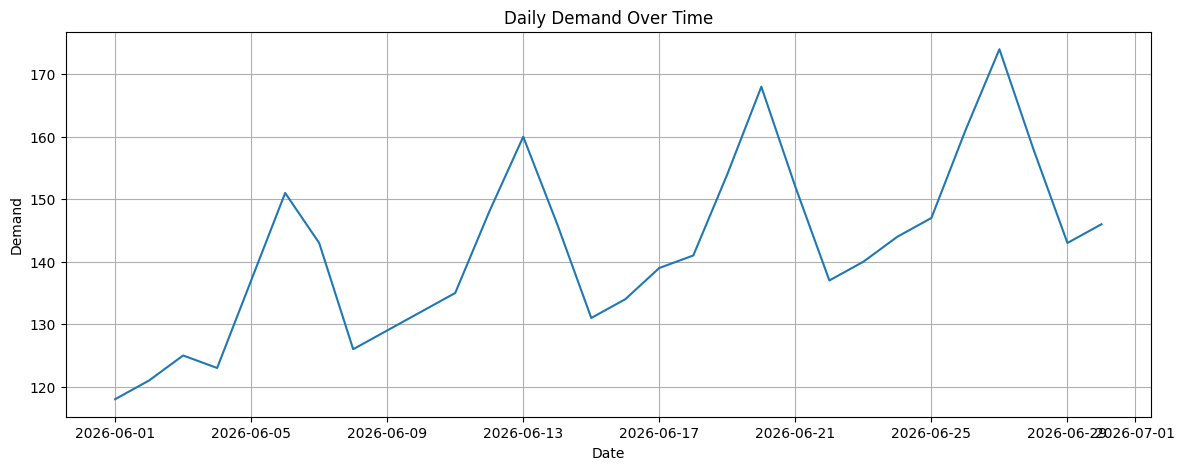

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(df.index, df["Demand"])
plt.title("Daily Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.grid(True)
plt.show()

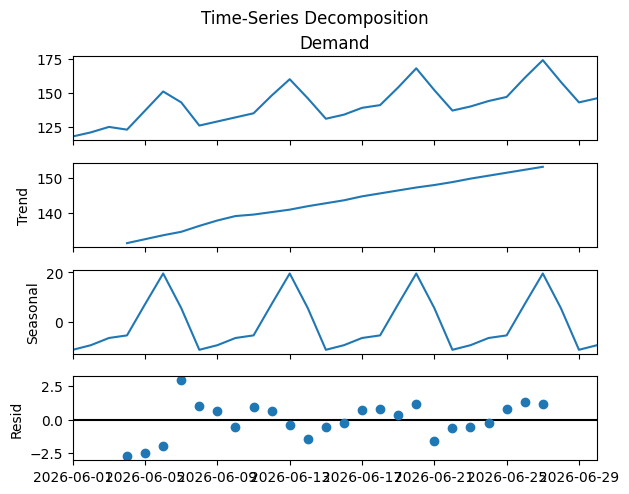

In [ ]:
if len(df) < 14:
    raise ValueError("At least 14 daily records are needed.")

decomposition = seasonal_decompose(
    df["Demand"],
    model="additive",
    period=7
)

decomposition.plot()
plt.suptitle("Time-Series Decomposition", y=1.02)
plt.show()

In [ ]:
adf_result = adfuller(df["Demand"].dropna())

print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])

if adf_result[1] < 0.05:
    print("The data is likely stationary.")
else:
    print("The data may not be stationary. Differencing may help.")

ADF Statistic: -0.9038698873856339
P-value: 0.7866953368372341
The data may not be stationary. Differencing may help.


In [ ]:
print("Total records:", len(df))
print(df.head())
print(df.tail())

Total records: 30
            Demand
date              
2026-06-01   118.0
2026-06-02   121.0
2026-06-03   125.0
2026-06-04   123.0
2026-06-05   137.0
            Demand
date              
2026-06-26   161.0
2026-06-27   174.0
2026-06-28   158.0
2026-06-29   143.0
2026-06-30   146.0


In [ ]:
total = len(df)

if total < 10:
    raise ValueError(
        "Too little data. Please check your dataset."
    )

test_size = max(1, int(total * 0.2))

train = df["Demand"].iloc[:-test_size]
test = df["Demand"].iloc[-test_size:]

print("Total records:", total)
print("Training records:", len(train))
print("Testing records:", len(test))

Total records: 30
Training records: 24
Testing records: 6


In [ ]:
best_aic = float("inf")
best_order = None
best_model = None

for p in range(3):
    for d in range(2):
        for q in range(3):
            try:
                model = ARIMA(
                    train,
                    order=(p, d, q)
                ).fit()

                if model.aic < best_aic:
                    best_aic = model.aic
                    best_order = (p, d, q)
                    best_model = model

            except Exception:
                continue

if best_model is None:
    raise ValueError("No ARIMA model could be fitted.")

print("Best ARIMA order:", best_order)
print("Best AIC score:", best_aic)

Best ARIMA order: (0, 0, 2)
Best AIC score: 166.33065311082615


In [ ]:
predictions = best_model.forecast(steps=len(test))
predictions.index = test.index

# MAPE: ignore actual zero values to avoid division by zero
actual = test.to_numpy()
predicted = predictions.to_numpy()

nonzero = actual != 0

if nonzero.any():
    mape = np.mean(
        np.abs(
            (actual[nonzero] - predicted[nonzero])
            / actual[nonzero]
        )
    ) * 100
else:
    mape = np.nan

# RMSE
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("MAPE:", round(mape, 2), "%" if not np.isnan(mape) else "")
print("RMSE:", round(rmse, 2))

MAPE: 10.44 %
RMSE: 19.94


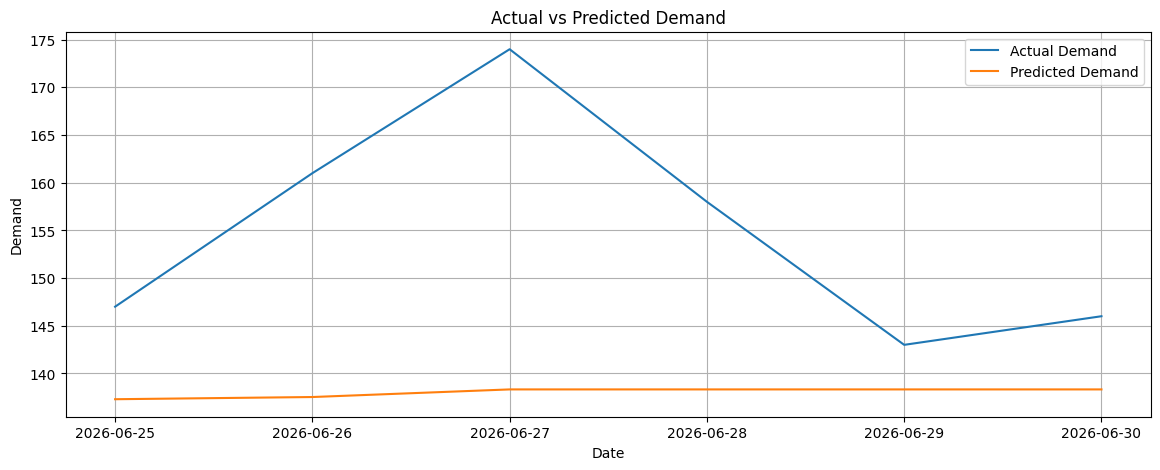

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(test.index, test, label="Actual Demand")
plt.plot(predictions.index, predictions, label="Predicted Demand")

plt.title("Actual vs Predicted Demand")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
final_model = ARIMA(
    df["Demand"],
    order=best_order
).fit()

future_forecast = final_model.forecast(steps=30)

future_dates = pd.date_range(
    start=df.index[-1] + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Demand": future_forecast.to_numpy()
})

print(forecast_df.to_string(index=False))

      Date  Predicted_Demand
2026-07-01        155.117909
2026-07-02        148.111515
2026-07-03        142.029913
2026-07-04        142.029913
2026-07-05        142.029913
2026-07-06        142.029913
2026-07-07        142.029913
2026-07-08        142.029913
2026-07-09        142.029913
2026-07-10        142.029913
2026-07-11        142.029913
2026-07-12        142.029913
2026-07-13        142.029913
2026-07-14        142.029913
2026-07-15        142.029913
2026-07-16        142.029913
2026-07-17        142.029913
2026-07-18        142.029913
2026-07-19        142.029913
2026-07-20        142.029913
2026-07-21        142.029913
2026-07-22        142.029913
2026-07-23        142.029913
2026-07-24        142.029913
2026-07-25        142.029913
2026-07-26        142.029913
2026-07-27        142.029913
2026-07-28        142.029913
2026-07-29        142.029913
2026-07-30        142.029913


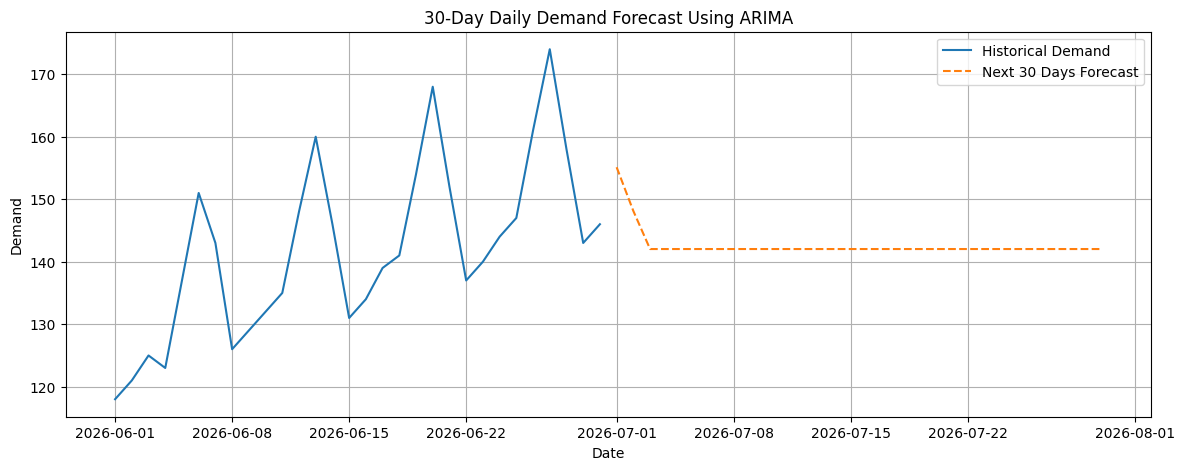

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    df.index[-90:],
    df["Demand"].iloc[-90:],
    label="Historical Demand"
)

plt.plot(
    future_dates,
    future_forecast,
    label="Next 30 Days Forecast",
    linestyle="--"
)

plt.title("30-Day Daily Demand Forecast Using ARIMA")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
forecast_df.to_csv(
    "30_day_demand_forecast.csv",
    index=False
)

print("Forecast saved successfully!")

from google.colab import files
files.download("30_day_demand_forecast.csv")

Forecast saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>